In [1]:
import torch
import matplotlib.pyplot as plt

Iter: 0, X:2.0, X.grad:16.0, Loss:16.0
Iter: 1, X:1.5199999809265137, X.grad:12.15999984741211, Loss:9.241600036621094
Iter: 2, X:0.7232000231742859, X.grad:5.785600185394287, Loss:2.0920732021331787
Iter: 3, X:-0.1674879789352417, X.grad:-1.3399038314819336, Loss:0.11220889538526535
Iter: 4, X:-0.9289100766181946, X.grad:-7.431280612945557, Loss:3.45149564743042
Iter: 5, X:-1.391251564025879, X.grad:-11.130012512207031, Loss:7.742323875427246
Iter: 6, X:-1.4734585285186768, X.grad:-11.787668228149414, Loss:8.684320449829102
Iter: 7, X:-1.193814754486084, X.grad:-9.550518035888672, Loss:5.700774669647217
Iter: 8, X:-0.6556198596954346, X.grad:-5.244958877563477, Loss:1.7193496227264404
Iter: 9, X:-0.013895690441131592, X.grad:-0.11116552352905273, Loss:0.000772360828705132
Iter: 10, X:0.5669910311698914, X.grad:4.535928249359131, Loss:1.2859153747558594
Iter: 11, X:0.953711211681366, X.grad:7.629689693450928, Loss:3.6382603645324707
Iter: 12, X:1.0728687047958374, X.grad:8.582949638366

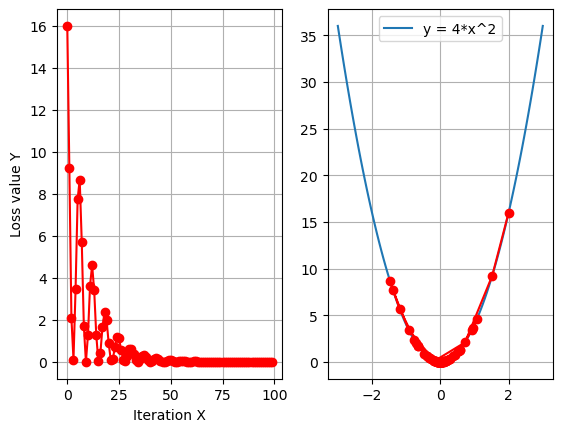

In [7]:
x = torch.tensor([2], requires_grad=True, dtype=torch.float)
#记录loss迭代次数， 画曲线
iter_rec, loss_rec, x_rec = list(), list(), list()

# 实验学习率： 0.01 0.02 0.03 0.1 0.2 0.3 0.4
lr = 0.01
# lr = 0.1    # 正常的梯度下降
# lr = 0.125      # 当学习率设置0.125 一下子求出一个最优解
# x=0 y=0 在x=0处梯度等于0 x的值x=x-lr*x.grad就不用更新了
# 后续再多少次迭代 都固定在最优点

# lr = 0.2      # x从2.0一下子跨过0点，到了左侧负数区域
#lr = 0.3
lr = 0.03
#optimizer = torch.optim.Adam([x], lr=lr, betas=(0.9, 0.99))
optimizer = torch.optim.SGD([x], lr=lr, momentum=0.9)
max_iteration = 100
for i in range(max_iteration):
    #计算损失
    loss = torch.pow(2* x, 2)  # 得出loss

    #梯度清零
    optimizer.zero_grad()
    #反向传播
    loss.backward()  # 计算x的梯度

    print(f"Iter: {i}, X:{x.detach().numpy()[0]}, X.grad:{x.grad.detach().numpy()[0]}, Loss:{loss.item()}")
    x_rec.append(x.item())
    iter_rec.append(i)
    loss_rec.append(loss.item())
    # 更新参数
    optimizer.step()

# 迭代次数-损失值 关系图
plt.subplot(121).plot(iter_rec, loss_rec, '-ro')
plt.grid()
plt.xlabel("Iteration X")
plt.ylabel("Loss value Y")
# 函数曲线-下降轨迹 显示图
x_t = torch.linspace(-3, 3, 100)
y = torch.pow(2* x_t, 2)
plt.subplot(122).plot(x_t.detach().numpy(), y.detach().numpy(), label="y = 4*x^2")
#plt.subplot(122).plot(x_t, y, label="y = 4*x^2")
y_rec = [torch.pow(2* torch.tensor(i), 2).item() for i in x_rec]
print('x_rec--->', x_rec)
print('y_rec--->', y_rec)
# 指定线的颜色和样式（-ro：红色圆圈，b-：蓝色实线等）
plt.subplot(122).plot(x_rec, y_rec, '-ro')
plt.grid()
plt.legend()
plt.show()